In [49]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import os
import glob
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

from sklearn.model_selection import train_test_split,cross_val_predict
from sklearn.base import clone
from sklearn.preprocessing  import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


from sklearn.metrics import f1_score,confusion_matrix,classification_report

# Read and Combine Data

In [50]:
folder_dir=os.path.join('..','data', 'raw', 'Power_data')
file_pattern=os.path.join(folder_dir,"Monitor_*.*")
all_files=glob.glob(file_pattern)
print(len(all_files))


dfs_list=[]
for file in all_files:
    df_temp=pd.read_excel(file,engine='openpyxl')
    df_temp['window'] = file
    dfs_list.append(df_temp)
    
main_df=pd.concat(dfs_list,ignore_index=True)





79


In [51]:
main_df.head()

,Timestamp,volt_A,volt_B,volt_C,I_A,I_B,I_C,P_A,P_B,P_C,...,Q_A,Q_B,Q_C,Q_T,FP_A,FP_B,FP_C,FP_T,Frec,window
0,2024-08-06 03:59:07.645,129.917,128.993,128.973,0.375,0.0,0.0,0.044,0.0,0.0,...,0.016,0.0,0.0,0.016,0.941,1.0,1.000,1.942,60.023,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
1,2024-08-06 04:09:08.641,129.558,128.800,129.294,0.088,0.0,0.0,0.007,0.0,0.0,...,0.005,0.0,0.0,0.005,0.835,1.0,1.000,1.837,59.986,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
2,2024-08-06 04:19:07.240,129.792,128.817,128.835,0.371,0.0,0.0,0.044,0.0,0.0,...,0.016,0.0,0.0,0.016,0.943,1.0,0.875,1.943,59.984,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
3,2024-08-06 04:29:08.141,129.550,128.699,129.328,0.088,0.0,0.0,0.007,0.0,0.0,...,0.005,0.0,0.0,0.005,0.830,1.0,1.000,1.837,59.957,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
4,2024-08-06 04:39:08.504,130.042,128.920,128.679,0.636,0.0,0.0,0.079,0.0,0.0,...,0.021,0.0,0.0,0.021,0.966,1.0,1.000,1.967,60.025,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...


In [52]:
rename_dict = {
    'P_A': 'Active_Power_A',
    'P_B': 'Active_Power_B',
    'P_C': 'Active_Power_C',
    'P_T': 'Total_Active_Power',
    'Q_A': 'Reactive_Power_A',
    'Q_B': 'Reactive_Power_B',
    'Q_C': 'Reactive_Power_C',
    'Q_T': 'Total_Reactive_Power',
    'FP_A': 'Power_Factor_A',
    'FP_B': 'Power_Factor_B',
    'FP_C': 'Power_Factor_C',
    'FP_T': 'Total_Power_Factor',
    'Frec': 'Freq'
}

main_df.rename(columns=rename_dict, inplace=True)

main_df.head()


,Timestamp,volt_A,volt_B,volt_C,I_A,I_B,I_C,Active_Power_A,Active_Power_B,Active_Power_C,...,Reactive_Power_A,Reactive_Power_B,Reactive_Power_C,Total_Reactive_Power,Power_Factor_A,Power_Factor_B,Power_Factor_C,Total_Power_Factor,Freq,window
0,2024-08-06 03:59:07.645,129.917,128.993,128.973,0.375,0.0,0.0,0.044,0.0,0.0,...,0.016,0.0,0.0,0.016,0.941,1.0,1.000,1.942,60.023,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
1,2024-08-06 04:09:08.641,129.558,128.800,129.294,0.088,0.0,0.0,0.007,0.0,0.0,...,0.005,0.0,0.0,0.005,0.835,1.0,1.000,1.837,59.986,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
2,2024-08-06 04:19:07.240,129.792,128.817,128.835,0.371,0.0,0.0,0.044,0.0,0.0,...,0.016,0.0,0.0,0.016,0.943,1.0,0.875,1.943,59.984,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
3,2024-08-06 04:29:08.141,129.550,128.699,129.328,0.088,0.0,0.0,0.007,0.0,0.0,...,0.005,0.0,0.0,0.005,0.830,1.0,1.000,1.837,59.957,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
4,2024-08-06 04:39:08.504,130.042,128.920,128.679,0.636,0.0,0.0,0.079,0.0,0.0,...,0.021,0.0,0.0,0.021,0.966,1.0,1.000,1.967,60.025,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...


In [53]:
main_df.shape

(33375, 21)

In [54]:
main_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33375 entries, 0 to 33374
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Timestamp             33375 non-null  datetime64[us]
 1   volt_A                33375 non-null  float64       
 2   volt_B                33375 non-null  float64       
 3   volt_C                33374 non-null  float64       
 4   I_A                   33374 non-null  float64       
 5   I_B                   33374 non-null  float64       
 6   I_C                   33374 non-null  float64       
 7   Active_Power_A        33374 non-null  float64       
 8   Active_Power_B        33374 non-null  float64       
 9   Active_Power_C        33374 non-null  float64       
 10  Total_Active_Power    33374 non-null  float64       
 11  Reactive_Power_A      33374 non-null  float64       
 12  Reactive_Power_B      33374 non-null  float64       
 13  Reactive_Power_C      33374

In [55]:
main_df = main_df.sort_values(['window','Timestamp']).reset_index(drop=True)
main_df = main_df.drop_duplicates(subset=['window','Timestamp']).reset_index(drop=True)
main_df

,Timestamp,volt_A,volt_B,volt_C,I_A,I_B,I_C,Active_Power_A,Active_Power_B,Active_Power_C,...,Reactive_Power_A,Reactive_Power_B,Reactive_Power_C,Total_Reactive_Power,Power_Factor_A,Power_Factor_B,Power_Factor_C,Total_Power_Factor,Freq,window
0,2024-08-06 03:59:07.645,129.917,128.993,128.973,0.375,0.000,0.0,0.044,0.000,0.0,...,0.016,0.000,0.0,0.016,0.941,1.000,1.000,1.942,60.023,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
1,2024-08-06 04:09:08.641,129.558,128.800,129.294,0.088,0.000,0.0,0.007,0.000,0.0,...,0.005,0.000,0.0,0.005,0.835,1.000,1.000,1.837,59.986,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
2,2024-08-06 04:19:07.240,129.792,128.817,128.835,0.371,0.000,0.0,0.044,0.000,0.0,...,0.016,0.000,0.0,0.016,0.943,1.000,0.875,1.943,59.984,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
3,2024-08-06 04:29:08.141,129.550,128.699,129.328,0.088,0.000,0.0,0.007,0.000,0.0,...,0.005,0.000,0.0,0.005,0.830,1.000,1.000,1.837,59.957,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
4,2024-08-06 04:39:08.504,130.042,128.920,128.679,0.636,0.000,0.0,0.079,0.000,0.0,...,0.021,0.000,0.0,0.021,0.966,1.000,1.000,1.967,60.025,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33370,2024-12-12 09:49:07.196,124.952,123.558,124.554,0.066,0.130,0.0,0.007,0.015,0.0,...,0.002,0.003,0.0,0.005,0.957,0.984,1.000,1.979,60.021,..\data\raw\Power_data\Monitor_variables_Prour...
33371,2024-12-12 09:59:07.464,124.548,123.442,124.460,0.000,0.130,0.0,0.000,0.015,0.0,...,0.000,0.003,0.0,0.003,0.000,0.981,1.000,1.987,60.039,..\data\raw\Power_data\Monitor_variables_Prour...
33372,2024-12-12 10:09:07.334,124.062,122.931,123.877,0.000,0.132,0.0,0.000,0.015,0.0,...,0.000,0.003,0.0,0.003,0.000,0.984,1.000,1.987,59.957,..\data\raw\Power_data\Monitor_variables_Prour...
33373,2024-12-12 10:19:07.344,124.981,124.048,124.923,0.000,0.130,0.0,0.000,0.015,0.0,...,0.000,0.003,0.0,0.003,0.000,0.981,1.000,1.987,60.012,..\data\raw\Power_data\Monitor_variables_Prour...


In [56]:
main_df.describe()

,Timestamp,volt_A,volt_B,volt_C,I_A,I_B,I_C,Active_Power_A,Active_Power_B,Active_Power_C,Total_Active_Power,Reactive_Power_A,Reactive_Power_B,Reactive_Power_C,Total_Reactive_Power,Power_Factor_A,Power_Factor_B,Power_Factor_C,Total_Power_Factor,Freq
count,33375,33375.000000,33375.000000,33374.000000,33374.000000,33374.000000,33374.00000,33374.000000,33374.000000,33374.000000,33374.000000,33374.000000,33374.000000,33374.000000,33371.000000,33368.000000,33367.000000,33367.000000,33367.000000,33342.000000
mean,2024-08-17 05:50:11.535041,127.174844,125.749994,126.550049,0.282324,0.342273,0.16880,0.030965,0.039451,0.006608,0.070333,0.013572,0.010000,0.019041,0.020954,0.805406,0.941449,0.768541,1.880728,60.033579
min,2024-04-22 17:01:39.264000,0.001000,0.001000,0.001000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001000,0.859000,0.000000
25%,2024-06-19 13:54:08.093500,125.495000,124.007000,124.966000,0.075000,0.000000,0.00000,0.007000,0.000000,0.000000,0.020000,0.003000,0.000000,0.000000,0.004000,0.778000,0.959000,0.533000,1.877000,59.971000
50%,2024-08-16 22:49:09.707000,126.915000,125.594000,126.526000,0.333000,0.201000,0.00000,0.038000,0.018000,0.000000,0.056000,0.013000,0.004000,0.000000,0.013000,0.924000,0.992000,1.000000,1.956000,59.990000
75%,2024-10-14 23:24:07.888000,128.825000,127.750000,128.257000,0.409000,0.523000,0.25000,0.047000,0.061000,0.015000,0.108000,0.018000,0.016000,0.025000,0.027000,0.949000,1.000000,1.000000,1.989000,60.012000
max,2024-12-12 10:29:08.239000,3604.480000,130.151000,130.890000,1.495000,2.487000,1.59500,0.290000,0.313000,0.067000,0.375000,0.129000,4.096000,2.377000,0.173000,1.000000,1.000000,1.000000,2.000000,129.735000
std,NaN,19.198605,2.739028,2.564005,0.240026,0.394525,0.27546,0.027403,0.048075,0.010211,0.060216,0.014477,0.038457,0.038469,0.024627,0.224285,0.105869,0.306396,0.205266,1.923253


====================================================================
               GRIDPULSE - DATA DESCRIBE() INSIGHTS
====================================================================

1. Meter Encoding Discovered (Total_Power_Factor):
   - The mean value is 1.88 and the max is 2.00. Physically, Power Factor cannot exceed 1.0. 
   - Insight: The meter adds 1.0 to the real PF values as a custom encoding. 
   - Action: We created a formula (PF_actual = Total_Power_Factor - 1) to get the true PF (Mean = 0.88).

2. Out-of-Range Sensor Errors (Spikes):
   - 'volt_A' showed a maximum value of 3604.48V (Normal mean is ~127V).
   - 'Freq' showed a maximum value of 129.7Hz (Normal mean is ~60Hz).
   - Insight: These are technical sensor spikes/errors, not real laboratory load behavior.
   - Action: Data quality filters were applied to remove any Voltage > 150V.

3. Scale of Operation (Lab Data vs. Real Factory):
   - 'Total_Active_Power' mean is extremely low (0.070 kW), and phase currents are around 0.2A.
   - Insight: This confirms the dataset belongs to a small university lab bench or testing kit, not a heavy industrial factory. 
   - Business Case Action: We present this as a "Proof of Concept (PoC)" to validate the AI algorithm logic.

4. Unbalanced Phase Loading:
   - Current 'I_B' (Mean = 0.34A) is much higher than 'I_A' (0.28A) and 'I_C' (0.16A).
   - Insight: There is an electrical imbalance between the three phases in the lab.
   - GridPulse Value: This will be used in our dashboard as a valuable operations insight for maintenance teams.


# Data Cleaning and Filtering

In [57]:
# Decode the Total Power Factor (Subtract 1 as discovered from data)

main_df['PF_actual'] = main_df['Total_Power_Factor']-1

In [58]:
main_df.describe()

,Timestamp,volt_A,volt_B,volt_C,I_A,I_B,I_C,Active_Power_A,Active_Power_B,Active_Power_C,...,Reactive_Power_A,Reactive_Power_B,Reactive_Power_C,Total_Reactive_Power,Power_Factor_A,Power_Factor_B,Power_Factor_C,Total_Power_Factor,Freq,PF_actual
count,33375,33375.000000,33375.000000,33374.000000,33374.000000,33374.000000,33374.00000,33374.000000,33374.000000,33374.000000,...,33374.000000,33374.000000,33374.000000,33371.000000,33368.000000,33367.000000,33367.000000,33367.000000,33342.000000,33367.000000
mean,2024-08-17 05:50:11.535041,127.174844,125.749994,126.550049,0.282324,0.342273,0.16880,0.030965,0.039451,0.006608,...,0.013572,0.010000,0.019041,0.020954,0.805406,0.941449,0.768541,1.880728,60.033579,0.880728
min,2024-04-22 17:01:39.264000,0.001000,0.001000,0.001000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001000,0.859000,0.000000,-0.141000
25%,2024-06-19 13:54:08.093500,125.495000,124.007000,124.966000,0.075000,0.000000,0.00000,0.007000,0.000000,0.000000,...,0.003000,0.000000,0.000000,0.004000,0.778000,0.959000,0.533000,1.877000,59.971000,0.877000
50%,2024-08-16 22:49:09.707000,126.915000,125.594000,126.526000,0.333000,0.201000,0.00000,0.038000,0.018000,0.000000,...,0.013000,0.004000,0.000000,0.013000,0.924000,0.992000,1.000000,1.956000,59.990000,0.956000
75%,2024-10-14 23:24:07.888000,128.825000,127.750000,128.257000,0.409000,0.523000,0.25000,0.047000,0.061000,0.015000,...,0.018000,0.016000,0.025000,0.027000,0.949000,1.000000,1.000000,1.989000,60.012000,0.989000
max,2024-12-12 10:29:08.239000,3604.480000,130.151000,130.890000,1.495000,2.487000,1.59500,0.290000,0.313000,0.067000,...,0.129000,4.096000,2.377000,0.173000,1.000000,1.000000,1.000000,2.000000,129.735000,1.000000
std,NaN,19.198605,2.739028,2.564005,0.240026,0.394525,0.27546,0.027403,0.048075,0.010211,...,0.014477,0.038457,0.038469,0.024627,0.224285,0.105869,0.306396,0.205266,1.923253,0.205266


In [59]:
P= main_df["Total_Active_Power"]
Q = main_df["Total_Reactive_Power"] 

main_df["apparent_power"] = np.sqrt(P ** 2 + Q ** 2)

# (power factor = active power/ total power)حساب معامل القدرة نظرياً بناءً على قوانين الفيزياء للتأكد من دقة العداد
main_df["PF_calc"] = P.abs() / main_df["apparent_power"].where(main_df["apparent_power"] > 0)


In [60]:
is_missing = P.isna() | Q.isna() | main_df["Total_Power_Factor"].isna()

is_no_load = (P==0) & (Q==0)

is_low_load = main_df['apparent_power'] < 0.02  #  apparent_power= sqrt(P^2 + Q^2). Below this the load is too small and PF is unstable.

upper_ok=main_df['PF_actual'] <= 1.0 #بفترض ان المصنع معندوش reactive power 
is_out_of_range = ~((main_df["PF_actual"] > 0) & upper_ok)

# هل هناك تضارب؟ (الفرق بين قراءة العداد الفعلي والقيمة المحسوبة فيزيائياً كبير؟)
is_inconsistent = (main_df["PF_actual"] - main_df["PF_calc"]).abs() > 0.05


In [61]:
# impossible physical values (Out of Range values from describe)

is_bad_voltage = (main_df['volt_A'] < 90) | (main_df['volt_A'] > 150)
is_bad_frequency = (main_df['Freq'] <= 55) | (main_df['Freq'] >= 65)

is_active_power_low = main_df['Total_Active_Power'] <= 0.001

In [62]:
main_df["drop_reason"] = np.select(
    [is_missing, is_no_load, is_low_load, is_out_of_range, is_inconsistent, is_bad_voltage, is_bad_frequency, is_active_power_low],
    ["missing_value", "no_load", "low_load", "pf_out_of_range", "pf_inconsistent", "bad_voltage", "bad_frequency", "low_active_power"],
    default="ok",
)

main_df["valid"] = main_df["drop_reason"] == "ok"


In [63]:
print(main_df['valid'].value_counts())
print(main_df['drop_reason'].value_counts())


valid
True     26163
False     7212
Name: count, dtype: int64
drop_reason
ok                 26163
low_load            4389
no_load             2661
pf_out_of_range       64
pf_inconsistent       63
bad_frequency         27
missing_value          8
Name: count, dtype: int64


In [64]:
columns_to_show = [
    "volt_A",               
    "Freq",                
    "PF_actual",           
    "apparent_power",       
    "Total_Active_Power",  
    "drop_reason",         
    "valid"              
]

display(main_df[columns_to_show].head(10))

dropped_rows = main_df[main_df["valid"] == False]
display(dropped_rows[columns_to_show].head(10))


,volt_A,Freq,PF_actual,apparent_power,Total_Active_Power,drop_reason,valid
0,129.917,60.023,0.942,0.047760,0.045,ok,True
1,129.558,59.986,0.837,0.008602,0.007,low_load,False
2,129.792,59.984,0.943,0.047760,0.045,ok,True
3,129.550,59.957,0.837,0.008602,0.007,low_load,False
4,130.042,60.025,0.967,0.081744,0.079,ok,True
5,129.884,59.975,0.968,0.052631,0.051,ok,True
6,129.890,60.016,0.962,0.082006,0.079,ok,True
7,129.638,59.961,0.959,0.043966,0.042,ok,True
8,129.595,59.953,0.943,0.046487,0.044,ok,True
9,129.291,59.959,0.826,0.008602,0.007,low_load,False


,volt_A,Freq,PF_actual,apparent_power,Total_Active_Power,drop_reason,valid
1,129.558,59.986,0.837,0.008602,0.007,low_load,False
3,129.550,59.957,0.837,0.008602,0.007,low_load,False
9,129.291,59.959,0.826,0.008602,0.007,low_load,False
11,129.169,60.004,0.916,0.017464,0.016,low_load,False
17,128.438,59.967,0.824,0.008602,0.007,low_load,False
115,129.052,60.018,0.926,0.017088,0.016,low_load,False
121,130.153,59.955,0.929,0.018385,0.017,low_load,False
123,128.627,59.963,0.835,0.008602,0.007,low_load,False
130,129.664,59.994,0.839,0.008602,0.007,low_load,False
131,129.664,60.029,0.828,0.008602,0.007,low_load,False


In [65]:

# PF_clean = PF only for valid rows, NaN for everything else.
main_df["PF_clean"] = main_df["PF_actual"].where(main_df["valid"])
main_df["P_clean"] = P.where(main_df["valid"])
main_df["Q_clean"] = Q.where(main_df["valid"])


In [66]:
main_df[['PF_clean','P_clean','Q_clean']]

,PF_clean,P_clean,Q_clean
0,0.942,0.045,0.016
1,NaN,NaN,NaN
2,0.943,0.045,0.016
3,NaN,NaN,NaN
4,0.967,0.079,0.021
...,...,...,...
33370,0.979,0.023,0.005
33371,NaN,NaN,NaN
33372,NaN,NaN,NaN
33373,NaN,NaN,NaN


In [67]:
main_df

,Timestamp,volt_A,volt_B,volt_C,I_A,I_B,I_C,Active_Power_A,Active_Power_B,Active_Power_C,...,Freq,window,PF_actual,apparent_power,PF_calc,drop_reason,valid,PF_clean,P_clean,Q_clean
0,2024-08-06 03:59:07.645,129.917,128.993,128.973,0.375,0.000,0.0,0.044,0.000,0.0,...,60.023,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...,0.942,0.047760,0.942215,ok,True,0.942,0.045,0.016
1,2024-08-06 04:09:08.641,129.558,128.800,129.294,0.088,0.000,0.0,0.007,0.000,0.0,...,59.986,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...,0.837,0.008602,0.813733,low_load,False,NaN,NaN,NaN
2,2024-08-06 04:19:07.240,129.792,128.817,128.835,0.371,0.000,0.0,0.044,0.000,0.0,...,59.984,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...,0.943,0.047760,0.942215,ok,True,0.943,0.045,0.016
3,2024-08-06 04:29:08.141,129.550,128.699,129.328,0.088,0.000,0.0,0.007,0.000,0.0,...,59.957,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...,0.837,0.008602,0.813733,low_load,False,NaN,NaN,NaN
4,2024-08-06 04:39:08.504,130.042,128.920,128.679,0.636,0.000,0.0,0.079,0.000,0.0,...,60.025,..\data\raw\Power_data\Monitor_Fri_Aug_09_2024...,0.967,0.081744,0.966438,ok,True,0.967,0.079,0.021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33370,2024-12-12 09:49:07.196,124.952,123.558,124.554,0.066,0.130,0.0,0.007,0.015,0.0,...,60.021,..\data\raw\Power_data\Monitor_variables_Prour...,0.979,0.023537,0.977176,ok,True,0.979,0.023,0.005
33371,2024-12-12 09:59:07.464,124.548,123.442,124.460,0.000,0.130,0.0,0.000,0.015,0.0,...,60.039,..\data\raw\Power_data\Monitor_variables_Prour...,0.987,0.015297,0.980581,low_load,False,NaN,NaN,NaN
33372,2024-12-12 10:09:07.334,124.062,122.931,123.877,0.000,0.132,0.0,0.000,0.015,0.0,...,59.957,..\data\raw\Power_data\Monitor_variables_Prour...,0.987,0.015297,0.980581,low_load,False,NaN,NaN,NaN
33373,2024-12-12 10:19:07.344,124.981,124.048,124.923,0.000,0.130,0.0,0.000,0.015,0.0,...,60.012,..\data\raw\Power_data\Monitor_variables_Prour...,0.987,0.015297,0.980581,low_load,False,NaN,NaN,NaN


# Build Target

In [68]:
PF_THRESHOLD = 0.90  #limit power factor
HORIZON_STEPS = 18 # 18 row represnt in our data 3 hours
SAMPLE_MINUTES = 10 # reading data every 10 minutes
EXPECTED_MINUTES = HORIZON_STEPS * SAMPLE_MINUTES #(18 * 10 = 180 minutes)

TOLERANCE = 15 # 15 minute

MIN_VALID_FUTURE = 10        # Min number of valid rows required in the future

MIN_CONSECUTIVE_LOW = 3      # Fault condition: must be low for 3 consecutive rows





main_df['is_low']=(main_df['PF_clean'] < PF_THRESHOLD ).astype(int)

# STEP 1: Find how many consecutive low-power readings we have in a row.
# We group by "window" to isolate each time frame, then use a moving window (rolling) to count.
# We use .transform() to keep the original DataFrame size, mapping the results back to each row.
low_run = main_df.groupby("window")['is_low'].transform(
    lambda s: s.rolling(MIN_CONSECUTIVE_LOW).sum()
)

main_df['event_end']=(low_run==MIN_CONSECUTIVE_LOW).astype(float)

In [69]:
main_df[['is_low','event_end']]

,is_low,event_end
0,0,0.0
1,0,0.0
2,0,0.0
3,0,0.0
4,0,0.0
...,...,...
33370,0,0.0
33371,0,0.0
33372,0,0.0
33373,0,0.0


In [70]:
#Look into the future rows inside each segment to check if any event occurs
# We shift up to 18 rows ahead to monitor the 3-hour future window
future_lows = [
    main_df.groupby("window")['event_end'].shift(-i) 
    for i in range(MIN_CONSECUTIVE_LOW, HORIZON_STEPS + 1)
]

any_future_event = pd.concat(future_lows, axis=1).max(axis=1) # 1 is low


In [71]:
# Check for time gap and protect model aganist gaps or missing hours
future_timestamp = main_df.groupby("window")['Timestamp'].shift(-HORIZON_STEPS)

actual_minutes_ahead = (future_timestamp -main_df['Timestamp']).dt.total_seconds()/60.0
time_is_continuous=actual_minutes_ahead.between(EXPECTED_MINUTES - TOLERANCE, EXPECTED_MINUTES + TOLERANCE)


# Ensure the future window contains enough valid load readings to make a decision

main_df['target'] = np.where(time_is_continuous & any_future_event, any_future_event, np.nan)
main_df['target'] = np.where(time_is_continuous &  main_df['target'].isna(), 0.0, main_df['target'])


In [72]:
print(main_df['target'].value_counts(dropna=False))

target
0.0    24368
1.0     6777
NaN     2230
Name: count, dtype: int64


In [73]:
print(main_df['event_end'].value_counts(dropna=False))


event_end
0.0    30629
1.0     2746
Name: count, dtype: int64


In [74]:
print(main_df['is_low'].value_counts())


is_low
0    27472
1     5903
Name: count, dtype: int64


In [75]:
print(main_df['PF_clean'].describe())


count    26163.000000
mean         0.919227
std          0.129825
min          0.057000
25%          0.912000
50%          0.961000
75%          0.993000
max          1.000000
Name: PF_clean, dtype: float64


In [76]:
main_df.isna().sum().sort_values(ascending=False)


Q_clean                 7212
P_clean                 7212
PF_clean                7212
PF_calc                 2666
target                  2230
Freq                      33
Power_Factor_B             8
Power_Factor_C             8
Total_Power_Factor         8
PF_actual                  8
Power_Factor_A             7
Total_Reactive_Power       4
apparent_power             4
Active_Power_A             1
volt_C                     1
I_C                        1
I_A                        1
I_B                        1
Active_Power_B             1
Reactive_Power_B           1
Active_Power_C             1
Reactive_Power_C           1
Total_Active_Power         1
Reactive_Power_A           1
Timestamp                  0
volt_B                     0
volt_A                     0
window                     0
drop_reason                0
valid                      0
is_low                     0
event_end                  0
dtype: int64

In [77]:
main_df.columns

Index(['Timestamp', 'volt_A', 'volt_B', 'volt_C', 'I_A', 'I_B', 'I_C',
       'Active_Power_A', 'Active_Power_B', 'Active_Power_C',
       'Total_Active_Power', 'Reactive_Power_A', 'Reactive_Power_B',
       'Reactive_Power_C', 'Total_Reactive_Power', 'Power_Factor_A',
       'Power_Factor_B', 'Power_Factor_C', 'Total_Power_Factor', 'Freq',
       'window', 'PF_actual', 'apparent_power', 'PF_calc', 'drop_reason',
       'valid', 'PF_clean', 'P_clean', 'Q_clean', 'is_low', 'event_end',
       'target'],
      dtype='str')

# Split and Preprossing 

In [78]:
main_df['Q_P_ratio'] = main_df['Total_Reactive_Power'] / (main_df['Total_Active_Power'].abs() + 1e-9)

main_df['hour'] = main_df['Timestamp'].dt.hour

coloums_to_keep=['hour', 'volt_A', 'volt_B', 'volt_C', 'I_A', 'I_B', 'I_C',
       'Total_Active_Power', 'Total_Reactive_Power',
       'Total_Power_Factor', 'Freq',
       'Q_P_ratio'
       ]

In [79]:
main_df[coloums_to_keep].info()

<class 'pandas.DataFrame'>
RangeIndex: 33375 entries, 0 to 33374
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   hour                  33375 non-null  int32  
 1   volt_A                33375 non-null  float64
 2   volt_B                33375 non-null  float64
 3   volt_C                33374 non-null  float64
 4   I_A                   33374 non-null  float64
 5   I_B                   33374 non-null  float64
 6   I_C                   33374 non-null  float64
 7   Total_Active_Power    33374 non-null  float64
 8   Total_Reactive_Power  33371 non-null  float64
 9   Total_Power_Factor    33367 non-null  float64
 10  Freq                  33342 non-null  float64
 11  Q_P_ratio             33371 non-null  float64
dtypes: float64(11), int32(1)
memory usage: 2.9 MB


In [80]:
df_ready = main_df[(main_df['valid'] == True) & (main_df['target'].notna())].copy()


In [81]:
X=df_ready[coloums_to_keep]
y=df_ready['target'].astype(int)

In [82]:
df_ready['target'].isna().sum()

np.int64(0)

In [83]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=45, stratify=y)
# Check shapes
print('X_train.shape \t', X_train.shape)
print('y_train.shape \t', y_train.shape)
print('***'*10)
print('X_test.shape \t', X_test.shape)
print('y_test.shape \t', y_test.shape)

X_train.shape 	 (19581, 12)
y_train.shape 	 (19581,)
******************************
X_test.shape 	 (4896, 12)
y_test.shape 	 (4896,)


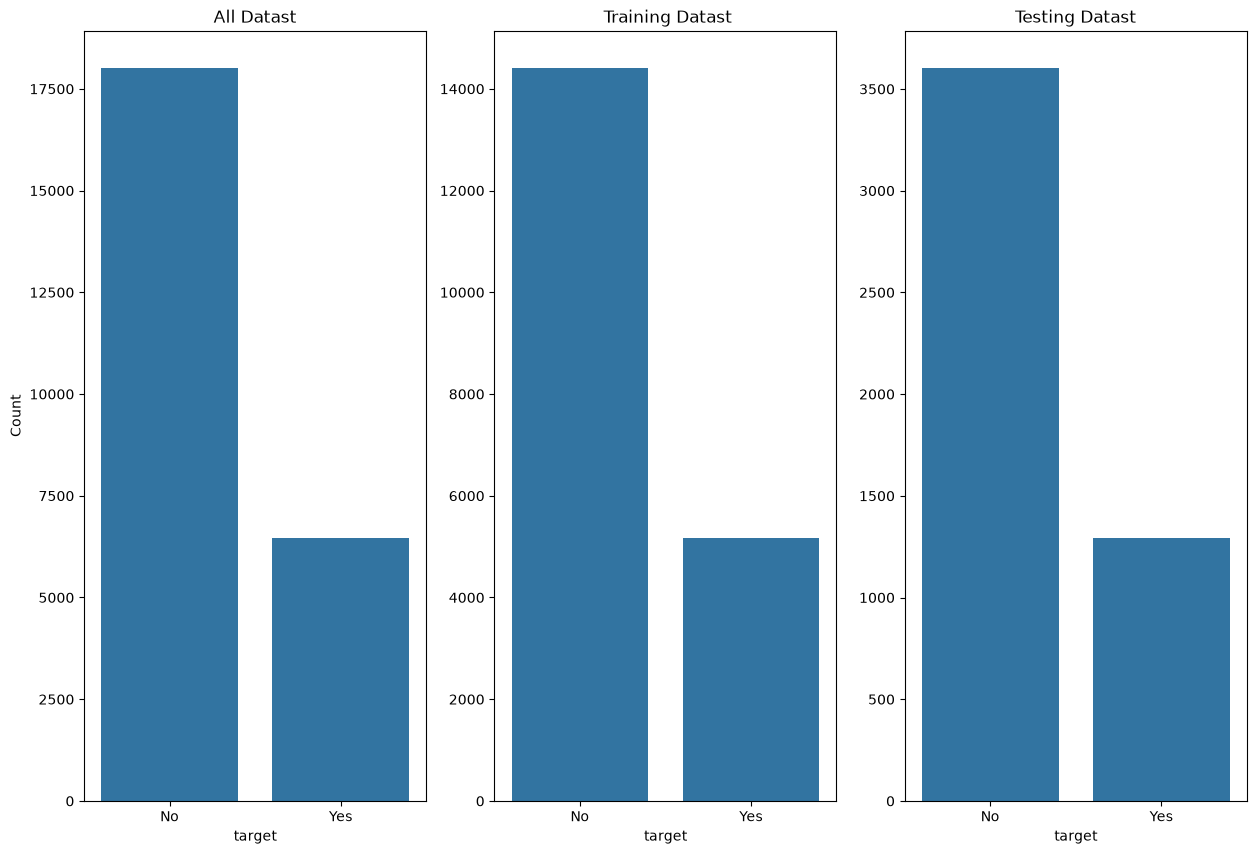

In [84]:
#plotting to check size of Exited

fig,ax=plt.subplots(1,3,figsize=(15,10))

plt.sca(ax[0])
sns.countplot(x=y)
plt.title('All Datast')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])

plt.sca(ax[1])
sns.countplot(x=y_train)
plt.title(' Training Datast')
plt.ylabel('')
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])


plt.sca(ax[2])
sns.countplot(x=y_test)
plt.title('Testing Datast')
plt.ylabel('')
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])
plt.show()



In [85]:
pass_feature=['Q_P_ratio','hour']
num_features = [
    'volt_A', 'volt_B', 'volt_C','I_A', 'I_B', 'I_C', 
    'Total_Active_Power', 'Total_Reactive_Power', 
    'Total_Power_Factor', 'Freq'
]


num_pipline=Pipeline(
    [
        ('imputer',SimpleImputer(strategy='median')),
        ('scalar',StandardScaler())
    ]
)

pass_pipline=Pipeline(
    [
        ('imputer',SimpleImputer(strategy='median'))
    ]
)



In [86]:
preprocessor=ColumnTransformer(
    [
        ('num',num_pipline,num_features),
        ('pass',pass_pipline,pass_feature)
        
    ]
)

In [87]:
# Create fodler for the models
MODEL_FOLDER_PATH=os.path.join(os.getcwd(),'..','model')
os.makedirs(MODEL_FOLDER_PATH, exist_ok=True)


In [88]:
# dump the preprocessor
joblib.dump(preprocessor, os.path.join(MODEL_FOLDER_PATH, 'preprocessor.pkl'))

['d:\\meqyas_api\\notebook\\..\\model\\preprocessor.pkl']

# Models

In [89]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

base_models={
    'LogisticRegression':LogisticRegression(class_weight='balanced',max_iter=100,random_state=45),
    'Random Forest':RandomForestClassifier(class_weight='balanced',n_estimators=200, max_depth=6, min_samples_leaf=20,
            n_jobs=-1, random_state=42),
    'XGBoost':xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.7, min_child_weight=20,
            reg_lambda=20, scale_pos_weight=scale_pos, n_jobs=-1, random_state=42),
}


In [90]:
rows = []
fitted = {}

for name, model in base_models.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])

    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline

    pred_train = pipeline.predict(X_train)
    pred_test = pipeline.predict(X_test)

    rows.append({
        "Model": name,
        "Train F1-Score": f1_score(y_train, pred_train),
        "Test F1-Score": f1_score(y_test, pred_test),
    })

    print(f"\nClassification Report for Model: {name}")
    print(classification_report(y_test, pred_test))



d:\meqyas_api\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Classification Report for Model: LogisticRegression
              precision    recall  f1-score   support

           0       0.89      0.79      0.84      3605
           1       0.55      0.73      0.63      1291

    accuracy                           0.77      4896
   macro avg       0.72      0.76      0.73      4896
weighted avg       0.80      0.77      0.78      4896


Classification Report for Model: Random Forest
              precision    recall  f1-score   support

           0       0.95      0.84      0.89      3605
           1       0.67      0.87      0.76      1291

    accuracy                           0.85      4896
   macro avg       0.81      0.86      0.82      4896
weighted avg       0.87      0.85      0.86      4896


Classification Report for Model: XGBoost
              precision    recall  f1-score   support

           0       0.96      0.84      0.89      3605
           1       0.67      0.90      0.77      1291

    accuracy                           

In [91]:
from sklearn.model_selection import StratifiedKFold,GridSearchCV

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=45)
def make_pip(model):
    return Pipeline(
        [
            ('prep',preprocessor),
            ('model',model)
        ]
    )

In [92]:
xgb_base=dict(n_jobs=1, random_state=42) 
g1=GridSearchCV(
    make_pip(xgb.XGBClassifier(n_estimators=300, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, reg_lambda=5, **xgb_base)),
    param_grid={
        'model__max_depth':[3,4,5],
        'model__min_child_weight':[15,10],
        'model__scale_pos_weight':[1, np.sqrt(scale_pos), scale_pos]
        },
    scoring='average_precision',cv=cv,n_jobs=-1
        
).fit(X_train,y_train)

p1 = {k.replace('model__', ''): v for k, v in g1.best_params_.items()}
print("Stage 1 Best Params:", p1)
print(f"Stage 1 Best Score: {g1.best_score_:.4f}")

###
g2=GridSearchCV(
    make_pip(xgb.XGBClassifier(n_estimators=300, learning_rate=0.03,**p1,**xgb_base)),
    param_grid={
        'model__subsample':[0.6,0.8,0.9],
        'model__colsample_bytree':[0.6,0.8,0.9]},
    scoring='average_precision',cv=cv,n_jobs=-1
    ).fit(X_train,y_train)

p2 = {k.replace('model__', ''): v for k, v in g2.best_params_.items()}
print("Stage 2 Best Params:", p2)
print(f"Stage 2 Best Score: {g2.best_score_:.4f}")

###
g3=GridSearchCV(
    make_pip(xgb.XGBClassifier(**p1,**p2,**xgb_base)),
    param_grid={
        'model__learning_rate': [0.01, 0.02, 0.03],
        'model__n_estimators': [300, 500, 800]},
    scoring='average_precision', cv=cv, n_jobs=-1
).fit(X_train, y_train)

print('Stage 3 (Final XGBoost Params):', g3.best_params_, "Score:", round(g3.best_score_, 4))
xgb_search = g3


Stage 1 Best Params: {'max_depth': 5, 'min_child_weight': 10, 'scale_pos_weight': np.float64(1.6708764287878544)}
Stage 1 Best Score: 0.8919
Stage 2 Best Params: {'colsample_bytree': 0.9, 'subsample': 0.8}
Stage 2 Best Score: 0.8941
Stage 3 (Final XGBoost Params): {'model__learning_rate': 0.03, 'model__n_estimators': 800} Score: 0.9055


In [93]:
best_xgb = xgb_search.best_estimator_
oof_probs = cross_val_predict(clone(best_xgb), X_train, y_train, cv=cv, method='predict_proba')[:, 1]   

thresholds = np.arange(0.05, 0.9, 0.01)
f1_scores = [f1_score(y_train, oof_probs >= t) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]

train_probs = best_xgb.predict_proba(X_train)[:, 1]
f1_train = f1_score(y_train,train_probs >= 0.50)
f1_train_tuned= f1_score(y_train, train_probs >= best_threshold)

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Train F1-Score @0.50: {f1_train:.3f}")
print(f"Train F1-Score Tuaned: {f1_train_tuned:.3f}")


test_probs = best_xgb.predict_proba(X_test)[:, 1]
f1_default = f1_score(y_test, test_probs >= 0.50)
f1_tuned = f1_score(y_test, test_probs >= best_threshold)

print(f"Test F1-Score @0.50: {f1_default:.3f}")
print(f"Test F1-Score Tuaned: {f1_tuned:.3f}")


Best Threshold: 0.50
Train F1-Score @0.50: 0.875
Train F1-Score Tuaned: 0.875
Test F1-Score @0.50: 0.822
Test F1-Score Tuaned: 0.822


In [94]:
final_model = xgb_search.best_estimator_

test_probabilities = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (test_probabilities >= best_threshold).astype(int)

print("======= XGBoost Power Factor Performance =======")
print(f"Threshold: {best_threshold}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_test):.3f}\n")

print("======= Detailed Report (Test Set) =======")
print(classification_report(y_test, y_pred_test, target_names=['Normal PF (0)', 'Low PF (1)']))

print("======= Confusion Matrix =======")
print(confusion_matrix(y_test, y_pred_test))


======= XGBoost Power Factor Performance =======
Threshold: 0.5000000000000001
Test F1-Score: 0.822

======= Detailed Report (Test Set) =======
               precision    recall  f1-score   support

Normal PF (0)       0.95      0.91      0.93      3605
   Low PF (1)       0.78      0.87      0.82      1291

     accuracy                           0.90      4896
    macro avg       0.87      0.89      0.88      4896
 weighted avg       0.91      0.90      0.90      4896

======= Confusion Matrix =======
[[3288  317]
 [ 169 1122]]


## Save data

In [95]:
df_ready.to_csv("../data/processed/power_factor.csv",index=False)

## Save model

In [96]:
joblib.dump({'pipeline': final_model, 'threshold': final_model}, os.path.join(MODEL_FOLDER_PATH, 'final_model.pkl'))

['d:\\meqyas_api\\notebook\\..\\model\\final_model.pkl']